# Finding the reactivation (win-back) cutoff: a closer look at purchase gaps

**Purpose**: the teammate responsible for H1 split reactivation events by month (1 month / 2 months / 3+ months). Here we
1. look at **weekly** granularity to find the point where the return rate bends (the elbow),
2. convert gaps into **multiples of the normal purchase cycle**, and
3. rebuild at the **household** level to see how many households each candidate cutoff affects.

As in the earlier EDA notebooks, this uses the 8 CSVs in the `data/` folder (only transaction_data is needed).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 100)

from config import DATA_DIR, OUT_DIR, INTERMEDIATE_DIR, FIG_DIR, SEED

tx = pd.read_csv(DATA_DIR / "transaction_data.csv")

print(tx.shape)
tx[["household_key", "DAY", "WEEK_NO", "BASKET_ID", "SALES_VALUE"]].head()


(2595732, 12)


,household_key,DAY,WEEK_NO,BASKET_ID,SALES_VALUE
0,2375,1,1,26984851472,1.39
1,2375,1,1,26984851472,0.82
2,2375,1,1,26984851472,0.99
3,2375,1,1,26984851472,1.21
4,2375,1,1,26984851472,1.50


In [2]:
import matplotlib.pyplot as plt

plt.rcParams["axes.unicode_minus"] = False  # keep the minus sign as a plain hyphen

## 1. Purchase-day (DAY) sequence per household and the gap between purchases

- For each household keep **only the days with a purchase**, drop duplicates and sort ascending
- Compute the interval between consecutive purchase days (gap, in days): the raw data for "how many days off before coming back"
- The first purchase has no previous purchase, so it has no gap (excluded)

In [3]:
# Unique household x purchase-day combinations
purchase_days = (
    tx[["household_key", "DAY"]]
    .drop_duplicates()
    .sort_values(["household_key", "DAY"], kind="stable")
)

# Per household, the difference from the previous purchase day (gap, in days)
purchase_days["prev_day"] = purchase_days.groupby("household_key")["DAY"].shift(1)
purchase_days["gap_days"] = purchase_days["DAY"] - purchase_days["prev_day"]

# Only real gap events (the first purchase, which has no gap, excluded)
gaps = purchase_days.dropna(subset=["gap_days"]).copy()
gaps["gap_days"] = gaps["gap_days"].astype(int)
gaps["gap_weeks"] = gaps["gap_days"] / 7

print(f"All gap events: {len(gaps):,}")
print(f"Unique households with a gap: {gaps['household_key'].nunique():,}")
gaps[["household_key", "prev_day", "DAY", "gap_days", "gap_weeks"]].head()


All gap events: 223,033


Unique households with a gap: 2,497


,household_key,prev_day,DAY,gap_days,gap_weeks
71711,1,51.0,67,16,2.285714
123815,1,67.0,88,21,3.000000
140773,1,88.0,94,6,0.857143
172266,1,94.0,101,7,1.000000
190170,1,101.0,108,7,1.000000


## 2. Define the normal purchase cycle

Use the **median** of the overall gap distribution as the "normal purchase cycle": most gaps are short repurchase intervals,
and a few long gaps (returning after being dormant) stretch the tail, so the median represents the distribution better than the mean.

In [4]:
normal_cycle_days = gaps["gap_days"].median()
print(f"Median of all gaps (normal purchase cycle): {normal_cycle_days:.1f} days (about {normal_cycle_days/7:.2f} weeks)")

print("\ngap_days distribution summary")
print(gaps["gap_days"].describe())

# How many multiples of the normal purchase cycle each gap is
gaps["gap_ratio"] = gaps["gap_days"] / normal_cycle_days

print("\ngap_ratio (multiple of the normal cycle) summary")
print(gaps["gap_ratio"].describe())


Median of all gaps (normal purchase cycle): 3.0 days (about 0.43 weeks)

gap_days distribution summary
count    223033.000000
mean          6.943869
std          15.870607
min           1.000000
25%           2.000000
50%           3.000000
75%           7.000000
max         666.000000
Name: gap_days, dtype: float64

gap_ratio (multiple of the normal cycle) summary
count    223033.000000
mean          2.314623
std           5.290202
min           0.333333
25%           0.666667
50%           1.000000
75%           2.333333
max         222.000000
Name: gap_ratio, dtype: float64


## 3. Weekly distribution: see where it actually bends (elbow)

Show the teammate's proposed 1-month (~4.3 weeks), 2-month (~8.6 weeks) and 3-month (~13 weeks) boundaries as dotted lines,
to compare directly how far the monthly buckets are from where the real distribution bends.

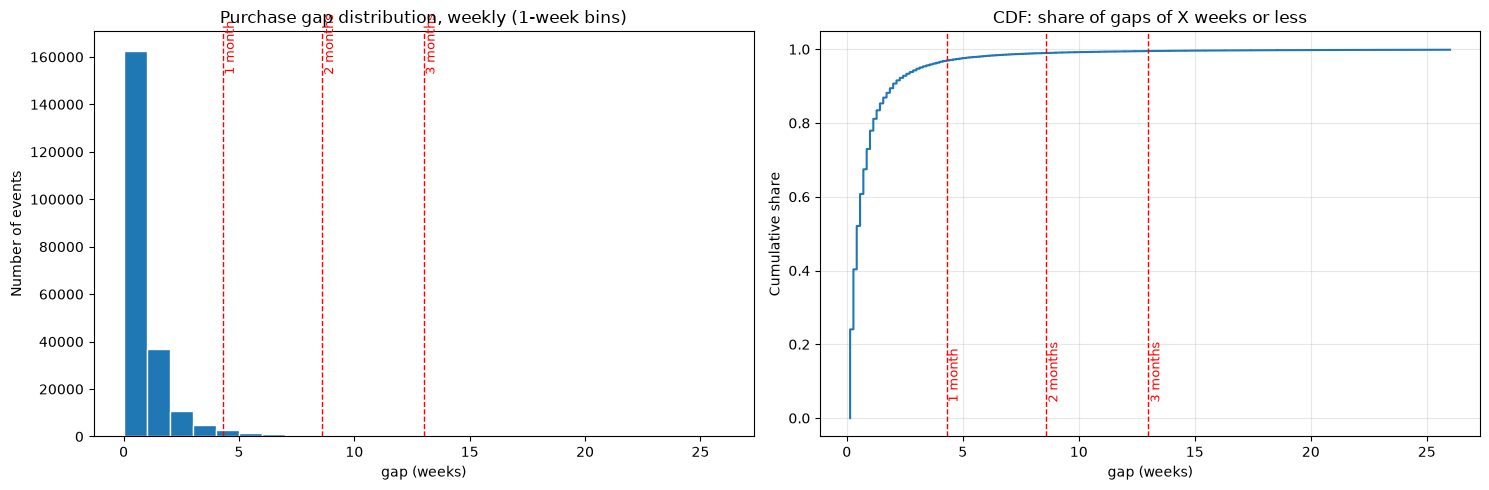

In [5]:
max_week_view = 26  # look at weeks 0-26 in 1-week steps (adjust if needed)

gap_weeks_clip = gaps["gap_weeks"][gaps["gap_weeks"] <= max_week_view]

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# (left) histogram, 1-week bins
bins = np.arange(0, max_week_view + 1, 1)
axes[0].hist(gap_weeks_clip, bins=bins, edgecolor='white')
for wk, label in [(4.3, '1 month'), (8.6, '2 months'), (13, '3 months')]:
    axes[0].axvline(wk, color='red', linestyle='--', linewidth=1)
    axes[0].text(wk, axes[0].get_ylim()[1]*0.9, label, rotation=90, color='red', fontsize=9)
axes[0].set_title("Purchase gap distribution, weekly (1-week bins)")
axes[0].set_xlabel("gap (weeks)")
axes[0].set_ylabel("Number of events")

# (right) cumulative distribution (CDF): share of all gaps that are X weeks or shorter
sorted_gaps = np.sort(gap_weeks_clip)
cdf = np.arange(1, len(sorted_gaps) + 1) / len(gaps)  # cumulative share of all gaps
axes[1].plot(sorted_gaps, cdf)
for wk, label in [(4.3, '1 month'), (8.6, '2 months'), (13, '3 months')]:
    axes[1].axvline(wk, color='red', linestyle='--', linewidth=1)
    axes[1].text(wk, 0.05, label, rotation=90, color='red', fontsize=9)
axes[1].set_title("CDF: share of gaps of X weeks or less")
axes[1].set_xlabel("gap (weeks)")
axes[1].set_ylabel("Cumulative share")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


## 4. Try automatic elbow detection

If the `kneed` package is available, let it find the elbow automatically; otherwise find by hand the point with the largest change in slope.
(To see where the repurchase probability drops sharply, use **the rate of decrease in the weekly gap frequency**, not the overall gap distribution.)

In [6]:
counts, edges = np.histogram(gap_weeks_clip, bins=bins)
week_centers = (edges[:-1] + edges[1:]) / 2

try:
    from kneed import KneeLocator
    kl = KneeLocator(week_centers, counts, curve="convex", direction="decreasing")
    print(f"Elbow point from the kneed package: about {kl.knee:.1f} weeks")
except ImportError:
    # Manual method: use the point with the largest rate of decrease (%) versus the adjacent bin as the approximate elbow
    pct_change = -np.diff(counts) / counts[:-1].clip(min=1) * 100
    elbow_idx = np.argmax(pct_change[:20])  # search only within 20 weeks
    print(f"(kneed not installed, manual approximation) bin with the largest decrease: around {week_centers[elbow_idx]:.1f} weeks")
    print("For exact automatic detection: pip install kneed --break-system-packages")

print("\nWeekly gap frequency (weeks 0-20)")
for w, c in zip(week_centers[:20], counts[:20]):
    print(f"  week {w:5.1f}: {c:6d} events")


Elbow point from the kneed package: about 2.5 weeks

Weekly gap frequency (weeks 0-20)
  week   0.5: 162655 events
  week   1.5:  36760 events
  week   2.5:  10771 events
  week   3.5:   4654 events
  week   4.5:   2562 events
  week   5.5:   1383 events
  week   6.5:    974 events
  week   7.5:    644 events
  week   8.5:    473 events
  week   9.5:    355 events
  week  10.5:    249 events
  week  11.5:    226 events
  week  12.5:    190 events
  week  13.5:    158 events
  week  14.5:    111 events
  week  15.5:     92 events
  week  16.5:     76 events
  week  17.5:     70 events
  week  18.5:     65 events
  week  19.5:     51 events


## 5. Check the same thing in multiples of the normal cycle (gap_ratio)

Instead of absolute weeks, cross-check whether the distribution bends at the same point when measured in "multiples of the normal purchase cycle".

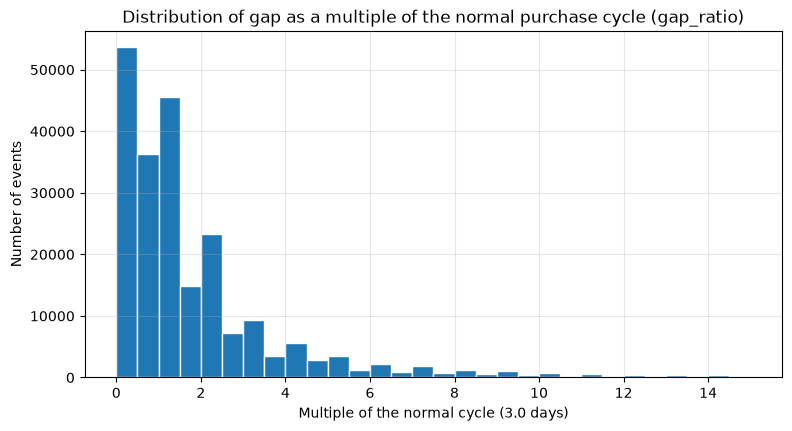

Events per multiple bin
gap_ratio
(0, 2]       162655
(2, 4]        33967
(4, 6]        11553
(6, 8]         5079
(8, 10]        2935
(10, 15]       3224
(15, 999]      3620
Name: count, dtype: int64


In [7]:
max_ratio_view = 15

ratio_clip = gaps["gap_ratio"][gaps["gap_ratio"] <= max_ratio_view]
ratio_bins = np.arange(0, max_ratio_view + 0.5, 0.5)

plt.figure(figsize=(9, 4.5))
plt.hist(ratio_clip, bins=ratio_bins, edgecolor='white')
plt.title("Distribution of gap as a multiple of the normal purchase cycle (gap_ratio)")
plt.xlabel(f"Multiple of the normal cycle ({normal_cycle_days:.1f} days)")
plt.ylabel("Number of events")
plt.grid(alpha=0.3)
plt.show()

print("Events per multiple bin")
print(pd.cut(gaps['gap_ratio'], bins=[0,2,4,6,8,10,15,999]).value_counts().sort_index())


## 6. Rebuild at the household level: households affected by each candidate cutoff

The teammate's analysis was **event-level** (one household can be reactivated several times).
Here, at the **household level**, we use each household's "longest gap (max gap)" to see how many households are classified as "reactivated" under each candidate cutoff
(a household with several reactivation events is counted once, to avoid double counting).

In [8]:
# Longest gap per household
household_max_gap = gaps.groupby("household_key")["gap_days"].max().reset_index()
household_max_gap.columns = ["household_key", "max_gap_days"]
household_max_gap["max_gap_weeks"] = household_max_gap["max_gap_days"] / 7

total_households = tx["household_key"].nunique()
print(f"All households: {total_households:,}")
print(f"Households with at least one gap event: {len(household_max_gap):,}")

candidate_cutoffs_weeks = [2, 4, 6, 8, 10, 13, 17, 26]  # about 2 weeks to 6 months

rows = []
for wk in candidate_cutoffs_weeks:
    n_households = (household_max_gap["max_gap_weeks"] >= wk).sum()
    rows.append({
        "cutoff_weeks": wk,
        "cutoff_months_equiv": round(wk / 4.3, 1),
        "households_classified_reactivated": n_households,
        "share_of_all_households_pct": round(n_households / total_households * 100, 1),
    })

cutoff_table = pd.DataFrame(rows)
cutoff_table


All households: 2,500
Households with at least one gap event: 2,497


,cutoff_weeks,cutoff_months_equiv,households_classified_reactivated,share_of_all_households_pct
0,2,0.5,2369,94.8
1,4,0.9,1928,77.1
2,6,1.4,1538,61.5
3,8,1.9,1264,50.6
4,10,2.3,1056,42.2
5,13,3.0,789,31.6
6,17,4.0,562,22.5
7,26,6.0,307,12.3


In [9]:
# For reference: highlight where the teammate's proposed 3-month (= 13-week) cutoff falls in the table
print("Result at the teammate's proposed cutoff (3 months = about 13 weeks):")
print(cutoff_table[cutoff_table["cutoff_weeks"] == 13])


Result at the teammate's proposed cutoff (3 months = about 13 weeks):
   cutoff_weeks  cutoff_months_equiv  households_classified_reactivated  \
5            13                  3.0                                789   

   share_of_all_households_pct  
5                         31.6  


## 7. Notes for the next step

- Check in plots 3 and 4 how many weeks the actual elbow is at, and compare it with the teammate's 13 weeks (3 months)
- Using the table in section 6, check how sensitively the number of reactivated households changes when the cutoff moves
  (if it changes sharply, that range is still an unstable boundary; recommend the point where it flattens out as the final cutoff)
- Once the final cutoff is set, attach a `customer_type` label (new / reactivated / existing) per `household_key` to `household_max_gap`
  and arrange it in the H1 output format (household_key | customer_type) -> connect it directly to the H4-2 cross-tab